# **Test Ligand Class**

In [ ]:
from src.protein import Protein

# Esempio di utilizzo
pdb_path = ".\\data\\raw\\P-L\\2011-2019\\2l7u\\2l7u_protein.pdb"
pdb_poket_path = ".\\data\\raw\\P-L\\2011-2019\\2l7u\\2l7u_pocket.pdb"

protein_pdb = Protein.from_pdb_code("2l7u")
protein_path = Protein.from_pdb_path(pdb_path)
pocket = Protein.from_pdb_path(pdb_poket_path)

protein_pdb.visualize_protein_3D()
protein_path.visualize_protein_3D()
pocket.visualize_protein_3D()

In [ ]:
print("proteina da PDB code:")
protein_pdb.visualize_protein_graph()
print("proteina da path:")
protein_path.visualize_protein_graph()
print("pocket:")
pocket.visualize_protein_graph()

In [3]:
protein= Protein.from_pdb_code("1L2Y")
protein.visualize_protein_graph()
x, edge_index, edge_attr, pos = protein.get_pyg_graph()

print(f"x: {x.shape}, edge_index: {edge_index.shape}, edge_attr: {edge_attr.shape}, pos: {pos.shape}")

print(edge_index)



x: torch.Size([20, 8]), edge_index: torch.Size([2, 180]), edge_attr: torch.Size([180, 2]), pos: torch.Size([20, 3])
tensor([[ 0,  1,  0,  0,  0,  2,  0,  3,  0,  4,  1,  2,  1,  1,  1,  3,  1,  4,
          1,  5,  1, 18,  2,  3,  2,  2,  2,  4,  2,  5,  2,  6,  2, 17,  2, 18,
          3,  4,  3,  3,  3,  5,  3,  6,  3,  7,  4,  5,  4,  4,  4,  6,  4,  7,
          4,  8,  5,  6,  5,  5,  5,  7,  5,  8,  5,  9,  5, 10,  5, 17,  5, 18,
          6,  7,  6,  6,  6,  8,  6,  9,  6, 10,  7,  8,  7,  7,  7,  9,  7, 10,
          8,  9,  8,  8,  8, 10,  8, 13,  9, 10,  9,  9,  9, 11,  9, 12,  9, 13,
         10, 11, 10, 10, 10, 12, 10, 13, 10, 15, 10, 16, 10, 17, 11, 12, 11, 11,
         11, 13, 11, 14, 11, 15, 11, 16, 11, 17, 12, 13, 12, 12, 12, 14, 12, 15,
         13, 14, 13, 13, 13, 15, 14, 15, 14, 14, 14, 16, 15, 16, 15, 15, 15, 17,
         16, 17, 16, 16, 16, 18, 17, 18, 17, 17, 17, 19, 18, 19, 18, 18, 19, 19],
        [ 1,  0,  0,  0,  2,  0,  3,  0,  4,  0,  2,  1,  1,  1,  3,  1, 

In [26]:
print("Node features (x): [amminoacido embedding 7D + b_factor]")
print("[idrofobicità, volume sterico, Polarizzabilità, polarità, Potenziale Isuelettrico, Indice di Refrattività, Propensione per l'Elica alpha] [b_factor]")
print (x)

graph = protein.graph
for n, d in graph.nodes(data=True):
    meiler_vals = list(d['meiler']) 
    print(f"{n} - Meiler: ["
        f"h1:{meiler_vals[0]:.2f}, "
        f"h2:{meiler_vals[1]:.2f}, "
        f"h3:{meiler_vals[2]:.2f}, "
        f"h4:{meiler_vals[3]:.2f}, "
        f"h5:{meiler_vals[4]:.2f}, "
        f"h6:{meiler_vals[5]:.2f}, "
        f"h7:{meiler_vals[6]:.2f}] "
        f"- B-factor: {d['b_factor']:.2f}")

Node features (x): [amminoacido embedding 7D + b_factor]
[idrofobicità, volume sterico, Polarizzabilità, polarità, Potenziale Isuelettrico, Indice di Refrattività, Propensione per l'Elica alpha] [b_factor]
tensor([[ 1.6000,  0.1300,  2.9500, -0.6000,  6.5200,  0.2100,  0.2200,  0.0000],
        [ 2.5900,  0.1900,  4.0000,  1.7000,  6.0400,  0.3900,  0.3100,  0.0000],
        [ 2.9400,  0.3000,  6.4700,  0.9600,  5.6600,  0.2500,  0.4100,  0.0000],
        [ 4.1900,  0.1900,  4.0000,  1.8000,  6.0400,  0.3000,  0.4500,  0.0000],
        [ 1.5600,  0.1800,  3.9500, -0.2200,  5.6500,  0.3500,  0.2500,  0.0000],
        [ 3.2100,  0.4100,  8.0800,  2.2500,  5.9400,  0.3200,  0.4200,  0.0000],
        [ 2.5900,  0.1900,  4.0000,  1.7000,  6.0400,  0.3900,  0.3100,  0.0000],
        [ 1.8900,  0.2200,  4.7700, -0.9900,  9.9900,  0.3200,  0.2700,  0.0000],
        [ 1.6000,  0.1100,  2.7800, -0.7700,  2.9500,  0.2500,  0.2000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  6.0700,  0

In [5]:
print(edge_attr)

for u, v, d in graph.edges(data=True):
    #print(d)
    print(f"Edge ({u}, {v}) - Type: {d['kind']} - Distance: {d['distance']:.2f} Å")

tensor([[3.8764, 1.0000],
        [3.8764, 1.0000],
        [0.0000, 0.0000],
        [0.0000, 0.0000],
        [5.5767, 0.0000],
        [5.5767, 0.0000],
        [5.0389, 0.0000],
        [5.0389, 0.0000],
        [6.3164, 0.0000],
        [6.3164, 0.0000],
        [3.8605, 1.0000],
        [3.8605, 1.0000],
        [0.0000, 0.0000],
        [0.0000, 0.0000],
        [5.4843, 0.0000],
        [5.4843, 0.0000],
        [5.2388, 0.0000],
        [5.2388, 0.0000],
        [6.4259, 0.0000],
        [6.4259, 0.0000],
        [6.9405, 0.0000],
        [6.9405, 0.0000],
        [3.8715, 1.0000],
        [3.8715, 1.0000],
        [0.0000, 0.0000],
        [0.0000, 0.0000],
        [5.4133, 0.0000],
        [5.4133, 0.0000],
        [4.9083, 0.0000],
        [4.9083, 0.0000],
        [6.1083, 0.0000],
        [6.1083, 0.0000],
        [7.1307, 0.0000],
        [7.1307, 0.0000],
        [6.3264, 0.0000],
        [6.3264, 0.0000],
        [3.8456, 1.0000],
        [3.8456, 1.0000],
        [0.0

tensor([[-8.6080,  3.1350, -1.6180],
        [-4.9230,  4.0020, -2.4520],
        [-3.6900,  2.7380,  0.9810],
        [-5.8570, -0.4490,  0.6130],
        [-4.1220, -1.1670, -2.7430],
        [-0.7160, -0.6310, -0.9930],
        [-1.6410, -2.9320,  1.9630],
        [-3.0240, -5.7910, -0.2690],
        [ 0.4660, -6.0160, -1.9050],
        [ 2.0600, -6.6180,  1.5930],
        [ 2.6260, -2.9670,  2.7230],
        [ 6.3330, -2.5330,  3.8060],
        [ 7.0490, -6.1790,  2.7040],
        [ 6.3890, -5.3150, -1.0150],
        [ 9.4510, -3.1160, -1.8700],
        [ 7.2890,  0.0840, -2.0540],
        [ 6.7820,  3.0880,  0.3450],
        [ 3.2870,  4.0310,  1.6860],
        [ 1.1850,  6.5430, -0.3530],
        [ 0.8520, 10.0270,  1.2850]])


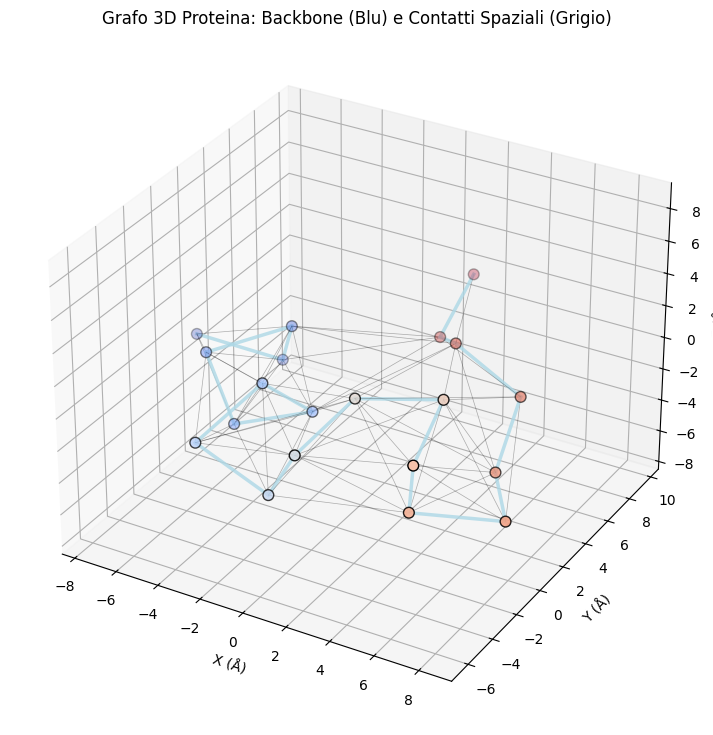

In [13]:
import matplotlib.pyplot as plt
import numpy as np

print(pos)
def plot_protein_graph_3d(pos, edge_index, edge_attr=None):
    """
    Visualizza il grafo della proteina in 3D usando Matplotlib.
    pos: tensore [N, 3] delle coordinate
    edge_index: tensore [2, E] degli indici dei legami
    edge_attr: opzionale, tensore [E, 2] dove la seconda colonna è il flag peptide_bond
    """
    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection='3d')

    # 1. DISEGNO DEI NODI
    # Usiamo una sfumatura basata sulla posizione nella sequenza (indice del nodo)
    colors = np.linspace(0, 1, pos.shape[0])
    scatter = ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], 
                         c=colors, cmap='coolwarm', s=60, edgecolors='black', depthshade=True)

    # 2. DISEGNO DEGLI ARCHI (Edges)
    # Iteriamo su edge_index. Nota: edge_index è bidirezionale, 
    # ne prendiamo solo metà o usiamo un set per non disegnare due volte la stessa linea.
    seen_edges = set()
    
    # Trasponiamo per iterare sulle coppie [src, dst]
    edges = edge_index.t().numpy()
    
    for i, (src, dst) in enumerate(edges):
        # Ordiniamo la coppia per evitare duplicati (u,v) == (v,u)
        edge = tuple(sorted((src, dst)))
        if edge in seen_edges:
            continue
        seen_edges.add(edge)

        # Coordinate dei due punti
        p1 = pos[src]
        p2 = pos[dst]

        # Definiamo stile e colore in base al tipo di legame (se disponibile)
        color = 'black'
        linewidth = 0.5
        alpha = 0.3
        
        if edge_attr is not None:
            is_peptide = edge_attr[i, 1].item() # La colonna 1 è il flag peptide
            if is_peptide == 1.0:
                color = 'lightblue'  
                linewidth = 2.5
                alpha = 0.8
        
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], 
                color=color, linewidth=linewidth, alpha=alpha)

    # Impostazioni grafiche
    ax.set_title('Grafo 3D Proteina: Backbone (Blu) e Contatti Spaziali (Grigio)')
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    
    # Per mantenere le proporzioni reali
    max_range = np.array([pos[:,0].max()-pos[:,0].min(), 
                          pos[:,1].max()-pos[:,1].min(), 
                          pos[:,2].max()-pos[:,2].min()]).max() / 2.0
    mid_x = (pos[:,0].max()+pos[:,0].min()) * 0.5
    mid_y = (pos[:,1].max()+pos[:,1].min()) * 0.5
    mid_z = (pos[:,2].max()+pos[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)

    plt.show()

# Esecuzione:
plot_protein_graph_3d(pos, edge_index, edge_attr)